In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("Mall_Customers.csv")

In [ ]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (200, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [ ]:
print("Gender Distribution:")
print(df["Gender"].value_counts())

Gender Distribution:
Gender
Female    112
Male       88
Name: count, dtype: int64


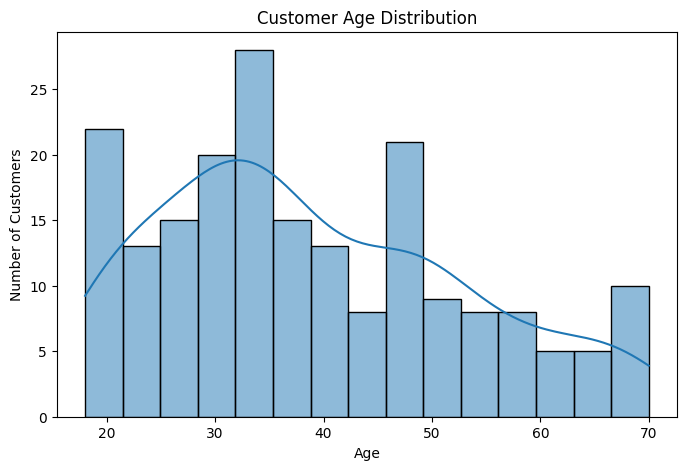

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["Age"], bins=15, kde=True)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

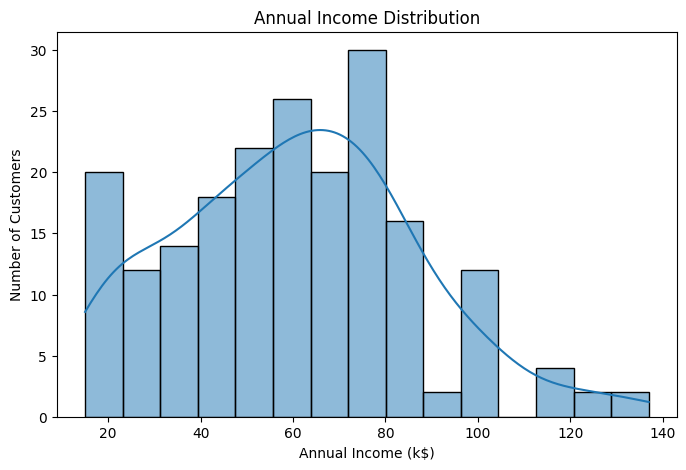

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["Annual Income (k$)"], bins=15, kde=True)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")

plt.show()

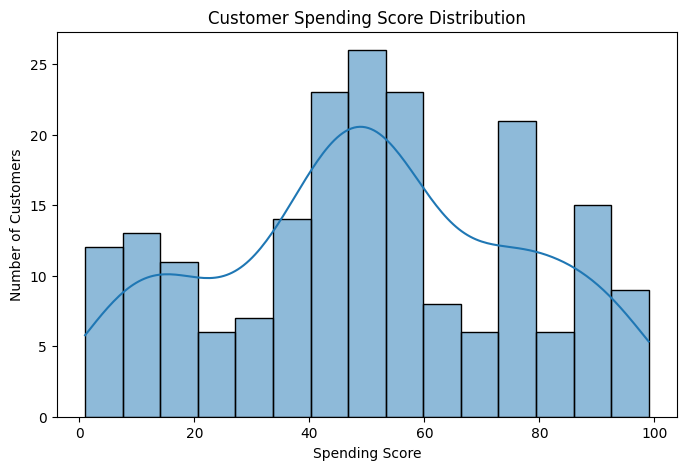

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["Spending Score (1-100)"], bins=15, kde=True)

plt.title("Customer Spending Score Distribution")
plt.xlabel("Spending Score")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

print("Selected Features:")
X.head()

Selected Features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [ ]:
from sklearn.cluster import KMeans

In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(X)

print("Customer Clustering Completed!")

df.head()

Customer Clustering Completed!


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


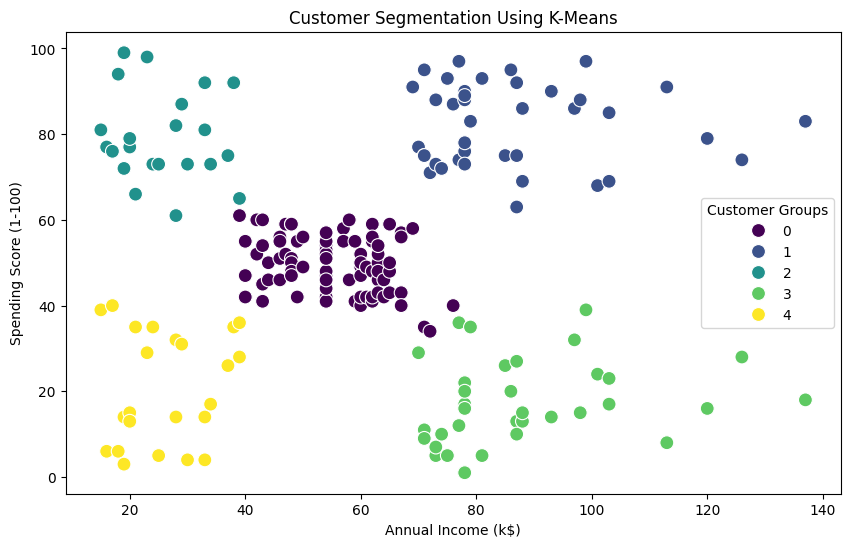

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.legend(title="Customer Groups")
plt.show()

In [ ]:
print("Number of Customers in Each Group:")
print(df["Cluster"].value_counts().sort_index())

Number of Customers in Each Group:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [ ]:
cluster_analysis = df.groupby("Cluster").agg({
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean",
    "CustomerID": "count"
})

cluster_analysis.rename(
    columns={"CustomerID": "Number of Customers"},
    inplace=True
)

print(cluster_analysis.round(2))

         Annual Income (k$)  Spending Score (1-100)  Number of Customers
Cluster                                                                 
0                     55.30                   49.52                   81
1                     86.54                   82.13                   39
2                     25.73                   79.36                   22
3                     88.20                   17.11                   35
4                     26.30                   20.91                   23


In [ ]:
segment_names = {
    0: "Average Customers",
    1: "Premium Customers",
    2: "Low Income High Spenders",
    3: "High Income Low Spenders",
    4: "Low Income Low Spenders"
}

df["Customer Segment"] = df["Cluster"].map(segment_names)

print(df[["CustomerID", "Annual Income (k$)",
          "Spending Score (1-100)",
          "Customer Segment"]].head(10))

   CustomerID  Annual Income (k$)  Spending Score (1-100)  \
0           1                  15                      39   
1           2                  15                      81   
2           3                  16                       6   
3           4                  16                      77   
4           5                  17                      40   
5           6                  17                      76   
6           7                  18                       6   
7           8                  18                      94   
8           9                  19                       3   
9          10                  19                      72   

           Customer Segment  
0   Low Income Low Spenders  
1  Low Income High Spenders  
2   Low Income Low Spenders  
3  Low Income High Spenders  
4   Low Income Low Spenders  
5  Low Income High Spenders  
6   Low Income Low Spenders  
7  Low Income High Spenders  
8   Low Income Low Spenders  
9  Low Income High Spenders 

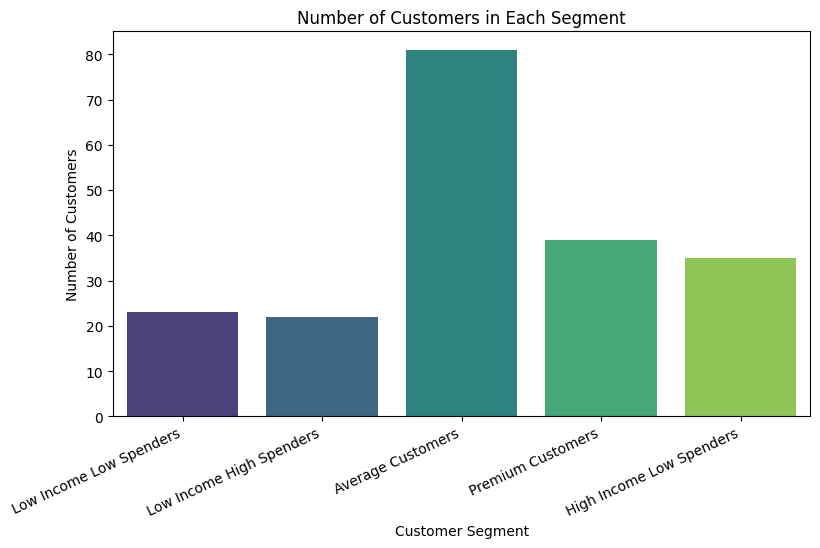

In [ ]:
plt.figure(figsize=(9,5))

sns.countplot(data=df, x="Customer Segment",
              hue="Customer Segment",
              palette="viridis", legend=False)

plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")

plt.show()

In [ ]:
segment_names = {
    0: "Average Customers",
    1: "Premium Customers",
    2: "Low Income High Spenders",
    3: "High Income Low Spenders",
    4: "Low Income Low Spenders"
}

df["Customer Segment"] = df["Cluster"].map(segment_names)

print(df[["CustomerID", "Annual Income (k$)",
          "Spending Score (1-100)",
          "Customer Segment"]].head(10))

   CustomerID  Annual Income (k$)  Spending Score (1-100)  \
0           1                  15                      39   
1           2                  15                      81   
2           3                  16                       6   
3           4                  16                      77   
4           5                  17                      40   
5           6                  17                      76   
6           7                  18                       6   
7           8                  18                      94   
8           9                  19                       3   
9          10                  19                      72   

           Customer Segment  
0   Low Income Low Spenders  
1  Low Income High Spenders  
2   Low Income Low Spenders  
3  Low Income High Spenders  
4   Low Income Low Spenders  
5  Low Income High Spenders  
6   Low Income Low Spenders  
7  Low Income High Spenders  
8   Low Income Low Spenders  
9  Low Income High Spenders 

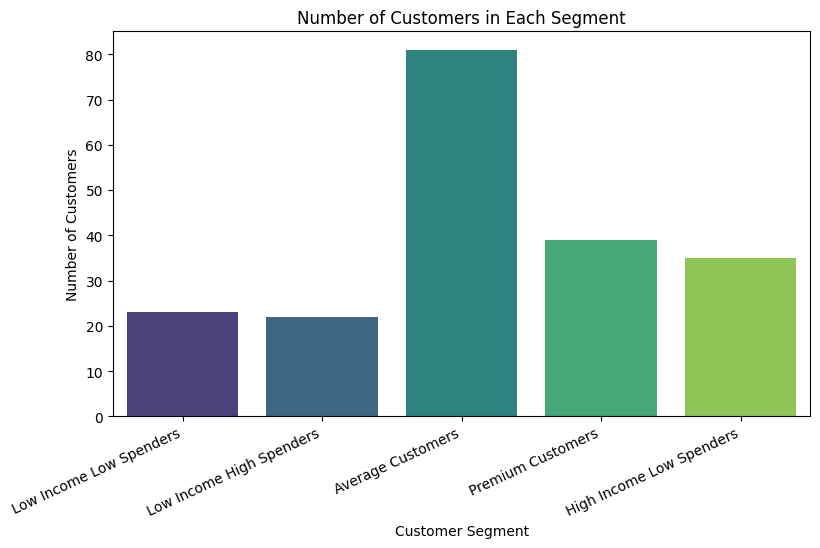

In [ ]:
plt.figure(figsize=(9,5))

sns.countplot(data=df, x="Customer Segment",
              hue="Customer Segment",
              palette="viridis", legend=False)

plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")

plt.show()

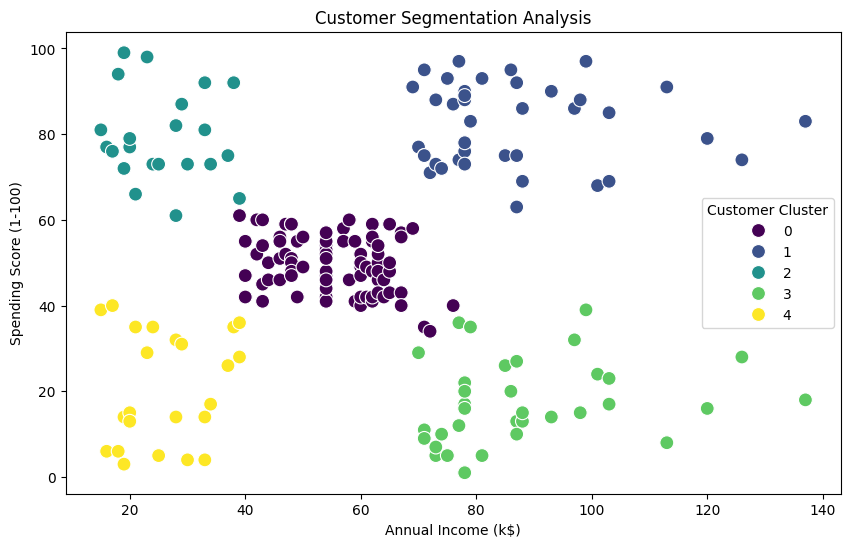

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.title("Customer Segmentation Analysis")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Cluster")
plt.show()

In [ ]:
cluster_summary = df.groupby("Cluster").agg({
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean",
    "CustomerID": "count"
}).round(2)

print("CUSTOMER SEGMENTATION SUMMARY")
print(cluster_summary)

CUSTOMER SEGMENTATION SUMMARY
         Annual Income (k$)  Spending Score (1-100)  CustomerID
Cluster                                                        
0                     55.30                   49.52          81
1                     86.54                   82.13          39
2                     25.73                   79.36          22
3                     88.20                   17.11          35
4                     26.30                   20.91          23


/tmp/ipykernel_2358/492995135.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


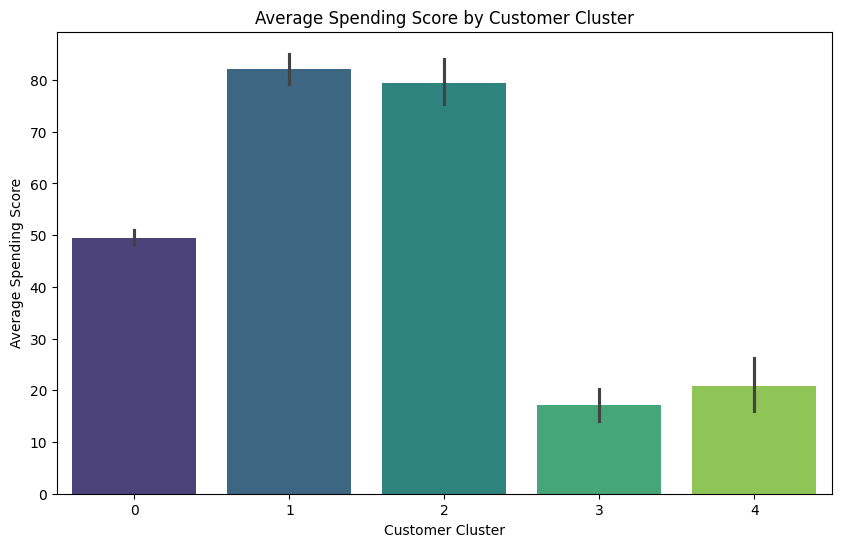

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Cluster",
    y="Spending Score (1-100)",
    palette="viridis"
)

plt.title("Average Spending Score by Customer Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Spending Score")
plt.show()

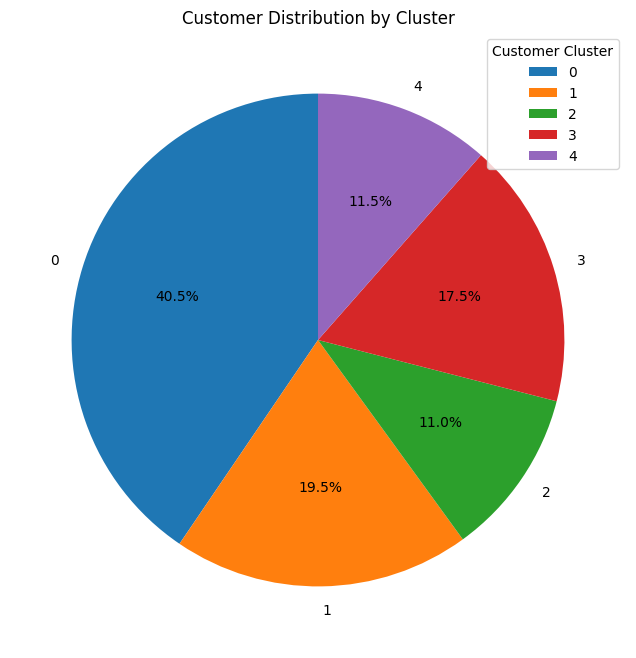

In [ ]:
cluster_counts = df["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 8))

plt.pie(
    cluster_counts,
    labels=cluster_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Distribution by Cluster")
plt.legend(title="Customer Cluster")
plt.show()

In [ ]:
print("CUSTOMER SEGMENTATION - BUSINESS INSIGHTS")

for cluster in sorted(df["Cluster"].unique()):
    group = df[df["Cluster"] == cluster]

    income = group["Annual Income (k$)"].mean()
    spending = group["Spending Score (1-100)"].mean()

    print("\nCluster:", cluster)
    print("Average Income:", round(income, 2))
    print("Average Spending Score:", round(spending, 2))

    if income > 60 and spending > 60:
        print("Insight: High-value customers. Offer loyalty rewards.")

    elif income > 60 and spending <= 60:
        print("Insight: High-income customers. Use personalized promotions.")

    elif income <= 60 and spending > 60:
        print("Insight: Potential customers. Encourage repeat purchases.")

    else:
        print("Insight: Low-income, low-spending customers. Offer budget deals.")

CUSTOMER SEGMENTATION - BUSINESS INSIGHTS

Cluster: 0
Average Income: 55.3
Average Spending Score: 49.52
Insight: Low-income, low-spending customers. Offer budget deals.

Cluster: 1
Average Income: 86.54
Average Spending Score: 82.13
Insight: High-value customers. Offer loyalty rewards.

Cluster: 2
Average Income: 25.73
Average Spending Score: 79.36
Insight: Potential customers. Encourage repeat purchases.

Cluster: 3
Average Income: 88.2
Average Spending Score: 17.11
Insight: High-income customers. Use personalized promotions.

Cluster: 4
Average Income: 26.3
Average Spending Score: 20.91
Insight: Low-income, low-spending customers. Offer budget deals.
